In [14]:
# Gaussian-process regression for foam property prediction
# Train one GPR model per response, evaluate leave-one-out performance,
# and compare predictions against the measured formulation data.
# generate 100000 candidate formulas and predict the 3 properties using the GPR models - using the copy of the data

In [15]:
# import data

from pathlib import Path
import pandas as pd

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
excel_path = project_root / 'data' / 'raw' / 'Copy of Compiled Data.xlsx'

df = pd.read_excel(excel_path)

print()

In [16]:
# Show the formulas and measured targets from the copied workbook.
formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
measured_target_cols = [
    "Avg_Density_g_cm3",
    "24h_avg_pct absorption",
    "24h_avg_pct_retention",
]
raw_data_summary = df[formula_cols + measured_target_cols].copy()
raw_data_summary[formula_cols] = raw_data_summary[formula_cols].fillna(0.0)
raw_data_summary[measured_target_cols] = raw_data_summary[measured_target_cols].apply(
    pd.to_numeric, errors="raise"
)

display(raw_data_summary)

,TEM,Joncryl,NC513,PEG-DE,NGDE,Avg_Density_g_cm3,24h_avg_pct absorption,24h_avg_pct_retention
0,8.0,0.0,0.0,0.0,0.0,0.192333,113.616943,29.321179
1,8.0,0.7,0.0,0.0,0.0,0.185000,103.817309,33.120000
2,8.0,1.0,0.0,0.0,0.0,0.164000,129.464292,36.250000
3,8.0,1.5,0.0,0.0,0.0,0.163500,120.749405,25.330000
4,8.0,2.0,0.0,0.0,0.0,0.190500,113.871581,26.580000
5,8.0,3.0,0.0,0.0,0.0,0.208500,111.044347,27.400000
6,5.0,0.0,0.0,0.0,0.0,0.300188,56.958538,36.614852
7,5.0,0.0,0.7,0.0,0.0,0.360035,57.115160,44.587460
8,5.0,0.0,1.0,0.0,0.0,0.355557,44.308895,44.916762
9,5.0,0.0,2.0,0.0,0.0,0.358055,43.326301,42.785828


,Ingredient,Property,n,Pearson r,Pearson p,Spearman rho,Spearman p
0,TEM,Avg_Density_g_cm3,23,-0.9086,0.0000,-0.7151,0.0001
1,TEM,24h_avg_pct absorption,21,0.6197,0.0027,0.7385,0.0001
2,TEM,24h_avg_pct_retention,25,-0.3556,0.0811,-0.4022,0.0463
3,Joncryl,Avg_Density_g_cm3,23,-0.3598,0.0918,-0.5218,0.0106
4,Joncryl,24h_avg_pct absorption,21,0.0794,0.7321,0.2746,0.2283
5,Joncryl,24h_avg_pct_retention,25,0.0391,0.8529,-0.0400,0.8493
6,NC513,Avg_Density_g_cm3,23,0.0049,0.9823,-0.0503,0.8197
7,NC513,24h_avg_pct absorption,21,-0.1631,0.4799,-0.4139,0.0622
8,NC513,24h_avg_pct_retention,25,0.2906,0.1588,0.3651,0.0727
9,PEG-DE,Avg_Density_g_cm3,23,-0.4016,0.0575,-0.4117,0.0510


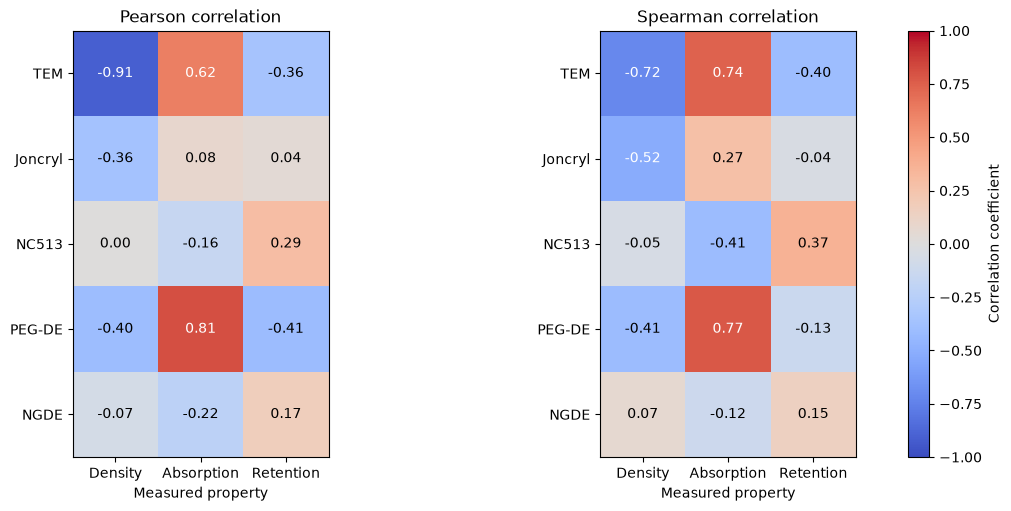

In [17]:
# pearson and spearman

import pandas as pd
from scipy.stats import pearsonr, spearmanr

feature_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
target_cols = [
    "Avg_Density_g_cm3",
    "24h_avg_pct absorption",
    "24h_avg_pct_retention",
]

rows = []

for ingredient in feature_cols:
    for target in target_cols:
        pair = df[[ingredient, target]].copy()

        # Blank chain-extender amounts mean that ingredient was not used.
        if ingredient != "TEM":
            pair[ingredient] = pair[ingredient].fillna(0)

        pair = pair.apply(pd.to_numeric, errors="coerce").dropna()

        r, pearson_p = pearsonr(pair[ingredient], pair[target])
        rho, spearman_p = spearmanr(pair[ingredient], pair[target])

        rows.append({
            "Ingredient": ingredient,
            "Property": target,
            "n": len(pair),
            "Pearson r": r,
            "Pearson p": pearson_p,
            "Spearman rho": rho,
            "Spearman p": spearman_p,
        })

correlations = pd.DataFrame(rows)
display(correlations.round(4))

import matplotlib.pyplot as plt
import numpy as np

target_labels = {
    "Avg_Density_g_cm3": "Density",
    "24h_avg_pct absorption": "Absorption",
    "24h_avg_pct_retention": "Retention",
}

heatmap_specs = [
    ("Pearson r", "Pearson correlation"),
    ("Spearman rho", "Spearman correlation"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

for ax, (value_col, title) in zip(axes, heatmap_specs):
    matrix = (
        correlations
        .pivot(index="Ingredient", columns="Property", values=value_col)
        .reindex(index=feature_cols, columns=target_cols)
    )

    image = ax.imshow(matrix.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)

    ax.set_xticks(
        range(len(target_cols)),
        labels=[target_labels[target] for target in target_cols],
    )
    ax.set_yticks(range(len(feature_cols)), labels=feature_cols)
    ax.set_title(title)
    ax.set_xlabel("Measured property")

    for row in range(len(feature_cols)):
        for col in range(len(target_cols)):
            value = matrix.iloc[row, col]
            ax.text(
                col,
                row,
                f"{value:.2f}",
                ha="center",
                va="center",
                color="white" if abs(value) >= 0.5 else "black",
            )

fig.colorbar(image, ax=axes, label="Correlation coefficient")
plt.show()


In [18]:
# Train one Gaussian process regressor per target, using all available measurements.

# gpr_models stores one model per target, each trained on rows with that target measured.

import numpy as np
from sklearn.base import clone
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

feature_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
target_cols = [
    "Avg_Density_g_cm3",
    "24h_avg_pct absorption",
    "24h_avg_pct_retention",
]

# Blank ingredient cells mean that ingredient was not used in the formula.
model_data = df[feature_cols + target_cols].copy()
model_data[feature_cols] = model_data[feature_cols].fillna(0.0)
model_data[target_cols] = model_data[target_cols].apply(pd.to_numeric, errors="raise")

X = model_data[feature_cols]
gpr_models = {}
cv_predictions = pd.DataFrame(index=model_data.index)
results = []

for target in target_cols:
    target_data = model_data.dropna(subset=[target])
    X_target = target_data[feature_cols]
    y = target_data[target]
    loo = LeaveOneOut()
    kernel = (
        ConstantKernel(1.0, (1e-3, 1e3))
        * Matern(
            length_scale=np.ones(len(feature_cols)),
            length_scale_bounds=(1e-2, 1e3),
            nu=2.5,
        )
        + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-8, 1e1))
    )
    estimator = make_pipeline(
        StandardScaler(),
        GaussianProcessRegressor(
            kernel=kernel,
            normalize_y=True,
            n_restarts_optimizer=5,
            random_state=42,
        ),
    )

    # cross_val_predict clones and refits the estimator for every held-out sample.
    oof_prediction = cross_val_predict(clone(estimator), X_target, y, cv=loo, n_jobs=1)
    cv_predictions.loc[target_data.index, f"{target} - LOOCV prediction"] = oof_prediction

    # Fit the final deployable model on all observations with this target; GPR optimizes kernel
    # hyperparameters by maximizing the log marginal likelihood during fit.
    final_model = clone(estimator).fit(X_target, y)
    gpr_models[target] = final_model

    results.append(
        {
            "target": target,
            "LOOCV R2": r2_score(y, oof_prediction),
            "LOOCV MAE": mean_absolute_error(y, oof_prediction),
            "LOOCV RMSE": np.sqrt(mean_squared_error(y, oof_prediction)),
            "training sample count": len(target_data),
            "optimized kernel": str(
                final_model.named_steps["gaussianprocessregressor"].kernel_
            ),
        }
    )

results_df = pd.DataFrame(results).set_index("target")
print("LOOCV performance:")
display(results_df)
print("\nFirst five out-of-fold predictions:")
display(cv_predictions.head())

c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-p

LOOCV performance:


c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,LOOCV R2,LOOCV MAE,LOOCV RMSE,training sample count,optimized kernel
target,,,,,
Avg_Density_g_cm3,0.884607,0.017287,0.022527,23,"1**2 * Matern(length_scale=[0.01, 2.32, 1.32, ..."
24h_avg_pct absorption,0.864309,22.083659,27.017929,21,"1.14**2 * Matern(length_scale=[0.232, 3.6, 20...."
24h_avg_pct_retention,0.750368,4.710812,6.307760,25,"0.911**2 * Matern(length_scale=[0.01, 0.467, 1..."



First five out-of-fold predictions:


,Avg_Density_g_cm3 - LOOCV prediction,24h_avg_pct absorption - LOOCV prediction,24h_avg_pct_retention - LOOCV prediction
0,0.202491,130.739621,31.324448
1,0.165555,123.855332,31.215531
2,0.169358,110.452788,36.596468
3,0.171130,115.236964,32.375718
4,0.172037,119.256647,29.846492


In [19]:
# save the 3 models to the folder models

from pathlib import Path
import joblib

project_root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(gpr_models, models_dir / "gpr_models.joblib")

['C:\\Users\\Brooke\\Foam project\\models\\gpr_models.joblib']

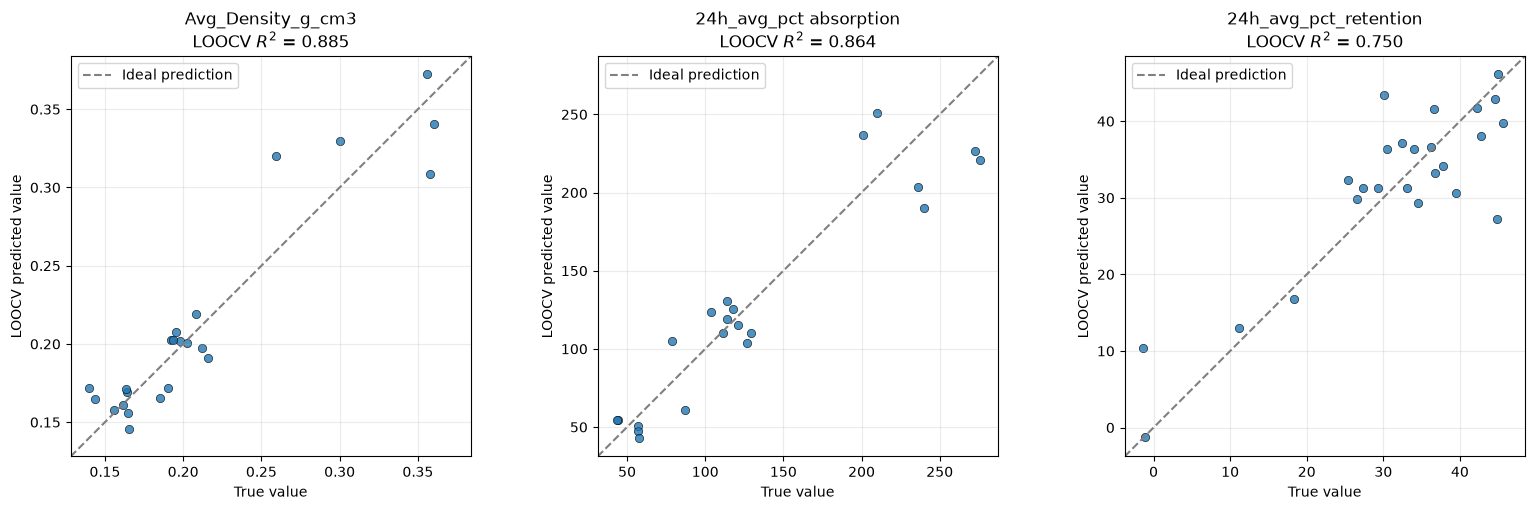

In [20]:
# Compare leave-one-out predictions with the measured values for each target.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(target_cols), figsize=(16, 5))

for ax, target in zip(axes, target_cols):
    observed = model_data[target].notna()
    y_true = model_data.loc[observed, target]
    y_pred = cv_predictions.loc[observed, f"{target} - LOOCV prediction"]
    score = r2_score(y_true, y_pred)
    lower = min(y_true.min(), y_pred.min())
    upper = max(y_true.max(), y_pred.max())
    padding = (upper - lower) * 0.05
    plot_min, plot_max = lower - padding, upper + padding

    ax.scatter(y_true, y_pred, alpha=0.8, edgecolor="black", linewidth=0.5)
    ax.plot([plot_min, plot_max], [plot_min, plot_max], "--", color="gray", label="Ideal prediction")
    ax.set_xlim(plot_min, plot_max)
    ax.set_ylim(plot_min, plot_max)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(f"{target}\nLOOCV $R^2$ = {score:.3f}")
    ax.set_xlabel("True value")
    ax.set_ylabel("LOOCV predicted value")
    ax.grid(alpha=0.25)
    ax.legend()

fig.tight_layout()
plt.show()

c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-p

Mean CV RMSE by property:


c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,Mean CV RMSE
Property,
24h_avg_pct absorption,33.4411
24h_avg_pct_retention,9.4961
Avg_Density_g_cm3,0.0241


Permutation importance: mean increase in held-out MSE


Property,Avg_Density_g_cm3,24h_avg_pct absorption,24h_avg_pct_retention
Ingredient,,,
TEM,0.00418,1966.07369,34.73867
Joncryl,0.00040,343.03099,87.77324
NC513,0.00050,10.59042,54.00523
PEG-DE,-0.00008,4045.36198,43.65556
NGDE,0.00003,139.20187,9.31726


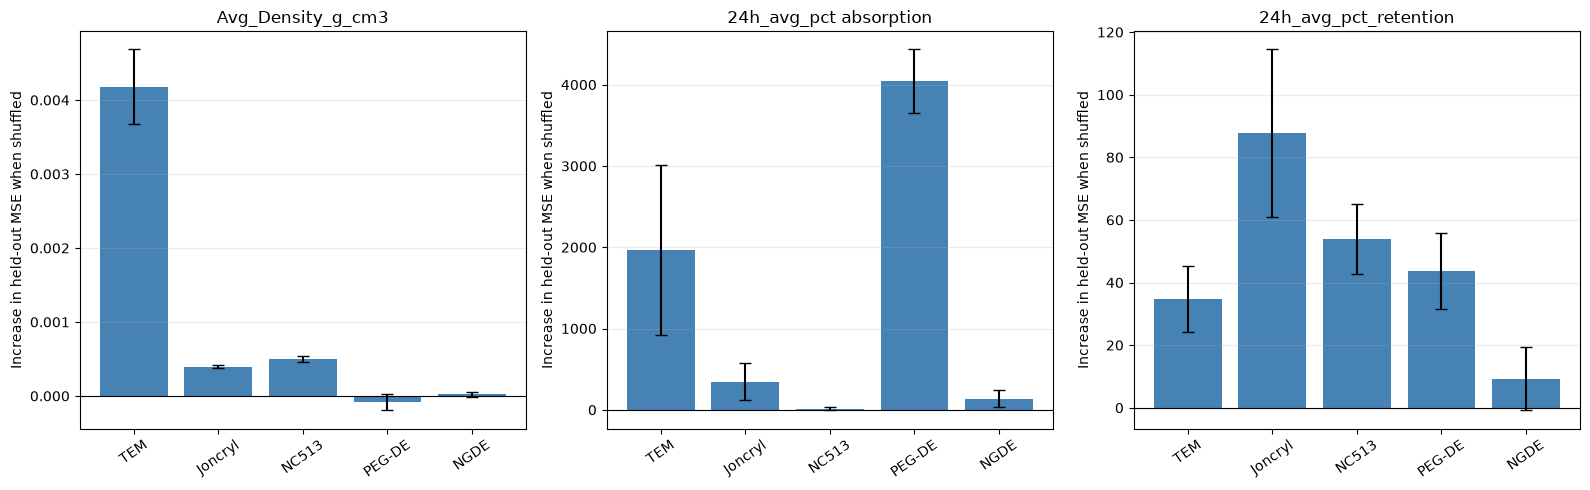

In [21]:
# permutation analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_squared_error

feature_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
target_cols = [
    "Avg_Density_g_cm3",
    "24h_avg_pct absorption",
    "24h_avg_pct_retention",
]

n_splits = 5
n_repeats = 3
n_permutations = 10
rng = np.random.default_rng(2026)

importance_rows = []
baseline_rows = []

for target in target_cols:
    target_data = df[feature_cols + [target]].copy()
    target_data[feature_cols] = target_data[feature_cols].fillna(0.0)
    target_data[target] = pd.to_numeric(target_data[target], errors="coerce")
    target_data = target_data.dropna(subset=[target])

    X_target = target_data[feature_cols]
    y_target = target_data[target].to_numpy()

    cv = RepeatedKFold(
        n_splits=n_splits,
        n_repeats=n_repeats,
        random_state=42,
    )
    split_iterator = iter(cv.split(X_target, y_target))

    for repeat in range(n_repeats):
        baseline_sse = 0.0
        permuted_sse = {
            feature: np.zeros(n_permutations)
            for feature in feature_cols
        }
        n_test = 0

        for _ in range(n_splits):
            train_idx, test_idx = next(split_iterator)
            X_train = X_target.iloc[train_idx]
            X_test = X_target.iloc[test_idx]
            y_train = y_target[train_idx]
            y_test = y_target[test_idx]

            # Clone the trained model's pipeline, then fit it only on this fold.
            fold_model = clone(gpr_models[target]).fit(X_train, y_train)

            baseline_pred = fold_model.predict(X_test)
            baseline_sse += np.sum((y_test - baseline_pred) ** 2)
            n_test += len(y_test)

            for feature in feature_cols:
                for permutation in range(n_permutations):
                    X_permuted = X_test.copy()
                    X_permuted[feature] = rng.permutation(
                        X_permuted[feature].to_numpy()
                    )
                    permuted_pred = fold_model.predict(X_permuted)
                    permuted_sse[feature][permutation] += np.sum(
                        (y_test - permuted_pred) ** 2
                    )

        baseline_mse = baseline_sse / n_test
        baseline_rows.append({
            "Property": target,
            "Repeat": repeat + 1,
            "CV RMSE": np.sqrt(baseline_mse),
        })

        for feature in feature_cols:
            delta_mse = permuted_sse[feature] / n_test - baseline_mse
            importance_rows.append({
                "Property": target,
                "Ingredient": feature,
                "Repeat": repeat + 1,
                "Importance": delta_mse.mean(),
            })

importance = pd.DataFrame(importance_rows)
importance_summary = (
    importance.groupby(["Property", "Ingredient"])["Importance"]
    .agg(["mean", "std"])
    .reset_index()
)

print("Mean CV RMSE by property:")
display(
    pd.DataFrame(baseline_rows)
    .groupby("Property")["CV RMSE"]
    .mean()
    .rename("Mean CV RMSE")
    .to_frame()
    .round(4)
)

print("Permutation importance: mean increase in held-out MSE")
display(
    importance_summary.pivot(
        index="Ingredient",
        columns="Property",
        values="mean",
    )
    .reindex(index=feature_cols, columns=target_cols)
    .round(5)
)

# Plot each target separately because their MSE scales differ.
fig, axes = plt.subplots(1, len(target_cols), figsize=(16, 5))

for ax, target in zip(axes, target_cols):
    target_summary = (
        importance_summary[importance_summary["Property"] == target]
        .set_index("Ingredient")
        .reindex(feature_cols)
    )

    ax.bar(
        feature_cols,
        target_summary["mean"],
        yerr=target_summary["std"],
        capsize=4,
        color="steelblue",
    )
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(target)
    ax.set_ylabel("Increase in held-out MSE when shuffled")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

In [ ]:
# Feasible-background partial dependence for each ingredient and GPR target.
# Chain-extender curves use only formulas that remain within the candidate constraints.
import numpy as np
import matplotlib.pyplot as plt

chain_extender_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]
feature_grids = {
    "TEM": np.linspace(5.0, 8.0, 25),
    **{
        ingredient: np.linspace(0.7, 3.0, 20)
        for ingredient in chain_extender_cols
    },
}

fig, axes = plt.subplots(
    len(target_cols),
    len(feature_cols),
    figsize=(18, 10),
    sharey="row",
)
feasible_counts = {}

for row, target in enumerate(target_cols):
    target_data = model_data.dropna(subset=[target])
    background = target_data[feature_cols].copy()
    background = background.loc[background["TEM"].between(5.0, 8.0)]
    model = gpr_models[target]

    for col, feature in enumerate(feature_cols):
        ax = axes[row, col]
        grid = feature_grids[feature]
        pd_means = []
        counts = []
        evaluation_values = (
            np.concatenate(([0.0], grid))
            if feature in chain_extender_cols
            else grid
        )

        for value in evaluation_values:
            X_eval = background.copy()
            X_eval[feature] = value

            if feature in chain_extender_cols:
                extender_values = X_eval[chain_extender_cols]
                levels_valid = (
                    extender_values.eq(0.0)
                    | (extender_values.ge(0.7) & extender_values.le(3.0))
                ).all(axis=1)
                total_valid = extender_values.sum(axis=1).between(0.7, 6.0)
                valid = levels_valid & total_valid
            else:
                valid = X_eval["TEM"].between(5.0, 8.0)

            X_eval = X_eval.loc[valid, feature_cols]
            counts.append(len(X_eval))
            if X_eval.empty:
                pd_means.append(np.nan)
            else:
                pd_means.append(model.predict(X_eval).mean())

        feasible_counts[(target, feature)] = counts
        if feature in chain_extender_cols:
            ax.plot(grid, pd_means[1:], color="steelblue", marker="o", markersize=3)
            ax.scatter([0.0], [pd_means[0]], color="steelblue", zorder=3)
            ax.set_xlim(-0.1, 3.1)
            ax.set_xticks([0.0, 0.7, 1.0, 2.0, 3.0])
        else:
            ax.plot(grid, pd_means, color="steelblue", marker="o", markersize=3)

        ax.grid(alpha=0.25)
        ax.set_title(feature if row == 0 else "")
        ax.set_xlabel("Ingredient level (%)")
        if col == 0:
            ax.set_ylabel(f"{target}\nAverage predicted value")
        ax.text(
            0.03,
            0.97,
            f"feasible backgrounds: {min(counts)}-{max(counts)}",
            transform=ax.transAxes,
            va="top",
            fontsize=8,
        )

fig.suptitle("GPR partial dependence over feasible formulas", y=1.02)
fig.tight_layout()
plt.show()

display(
    pd.DataFrame(
        [
            {
                "Property": target,
                "Ingredient": feature,
                "Minimum feasible backgrounds": min(feasible_counts[(target, feature)]),
                "Maximum feasible backgrounds": max(feasible_counts[(target, feature)]),
            }
            for target in target_cols
            for feature in feature_cols
        ]
    )
)

In [22]:
# Interactive 3D comparison for rows with all three measured targets.
import plotly.graph_objects as go

complete_target_data = model_data.dropna(subset=target_cols)
measured_values = complete_target_data[target_cols].to_numpy(dtype=float)
predicted_values = cv_predictions.loc[
    complete_target_data.index,
    [f"{target} - LOOCV prediction" for target in target_cols],
].to_numpy(dtype=float)
formula_values = complete_target_data[feature_cols].to_numpy(dtype=float)

# Draw connectors first so the measured and predicted markers remain prominent.
connector_x, connector_y, connector_z = [], [], []
for measured, predicted in zip(measured_values, predicted_values):
    connector_x.extend([measured[0], predicted[0], None])
    connector_y.extend([measured[1], predicted[1], None])
    connector_z.extend([measured[2], predicted[2], None])

fig = go.Figure()
fig.add_trace(
    go.Scatter3d(
        x=connector_x,
        y=connector_y,
        z=connector_z,
        mode="lines",
        line=dict(color="gray", width=2),
        opacity=0.35,
        hoverinfo="skip",
        showlegend=False,
        name="Prediction error",
    )
)

formula_hover = [
    "<br>".join(f"{name}: {value:g}" for name, value in zip(feature_cols, formula))
    for formula in formula_values
]

fig.add_trace(
    go.Scatter3d(
        x=measured_values[:, 0],
        y=measured_values[:, 1],
        z=measured_values[:, 2],
        mode="markers",
        name="Measured",
        marker=dict(size=6, color="#1769aa", symbol="circle", opacity=0.9),
        text=formula_hover,
        hovertemplate=(
            "<b>Measured</b><br>Density: %{x:.3f} g/cm^3"
            "<br>Absorption: %{y:.2f}%<br>Retention: %{z:.2f}%"
            "<br>%{text}<extra></extra>"
        ),
    )
)
fig.add_trace(
    go.Scatter3d(
        x=predicted_values[:, 0],
        y=predicted_values[:, 1],
        z=predicted_values[:, 2],
        mode="markers",
        name="GPR LOOCV prediction",
        marker=dict(size=6, color="#e87519", symbol="diamond", opacity=0.9),
        text=formula_hover,
        hovertemplate=(
            "<b>LOOCV prediction</b><br>Density: %{x:.3f} g/cm^3"
            "<br>Absorption: %{y:.2f}%<br>Retention: %{z:.2f}%"
            "<br>%{text}<extra></extra>"
        ),
    )
)

fig.update_layout(
    title="Measured outcomes vs. GPR LOOCV predictions",
    scene=dict(
        xaxis_title="Density (g/cm^3)",
        yaxis_title="24 h absorption (%)",
        zaxis_title="24 h retention (%)",
        aspectmode="data",
    ),
    height=700,
    margin=dict(l=0, r=0, b=0, t=55),
    legend=dict(x=0.02, y=0.98),
)
fig.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

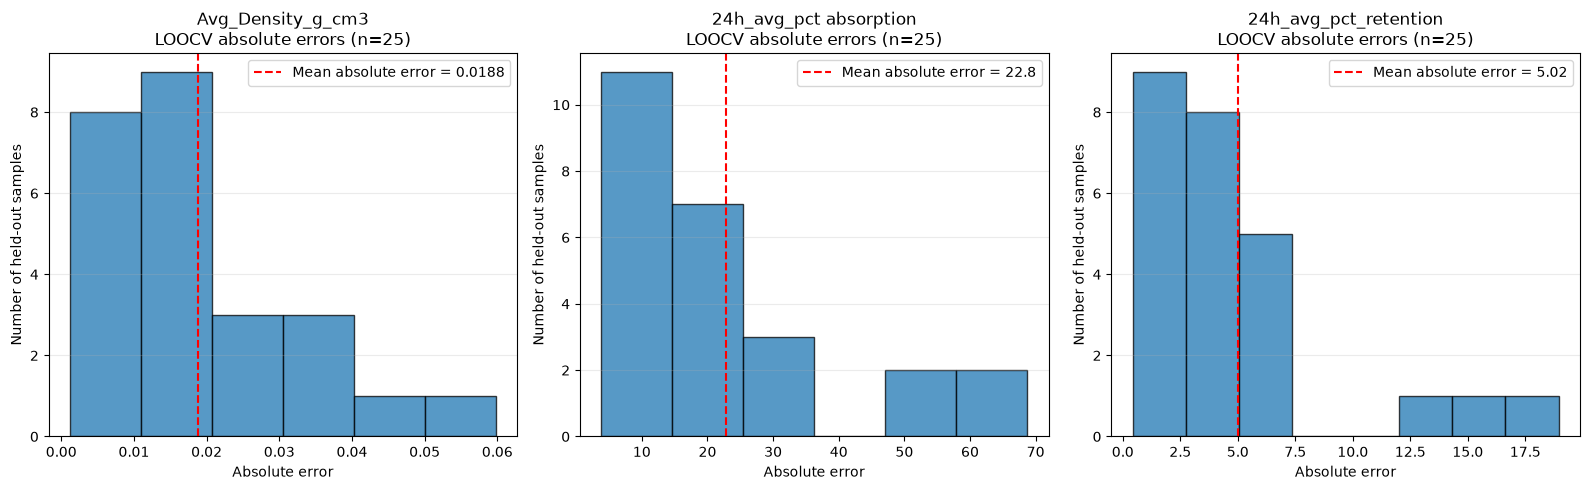

In [ ]:
# Show the distribution of absolute errors across the available LOOCV folds.

absolute_errors = pd.DataFrame(index=model_data.index)
for target in target_cols:
    absolute_errors[target] = (
        model_data[target] - cv_predictions[f"{target} - LOOCV prediction"]
    ).abs()

fig, axes = plt.subplots(1, len(target_cols), figsize=(16, 5))

for ax, target in zip(axes, target_cols):
    errors = absolute_errors[target].dropna()
    ax.hist(errors, bins="auto", edgecolor="black", alpha=0.75)
    ax.axvline(
        errors.mean(),
        color="red",
        linestyle="--",
        label=f"Mean absolute error = {errors.mean():.3g}",
    )
    ax.set_title(f"{target}\nLOOCV absolute errors (n={len(errors)})")
    ax.set_xlabel("Absolute error")
    ax.set_ylabel("Number of held-out samples")
    ax.grid(axis="y", alpha=0.25)
    ax.legend()

fig.tight_layout()
plt.show()

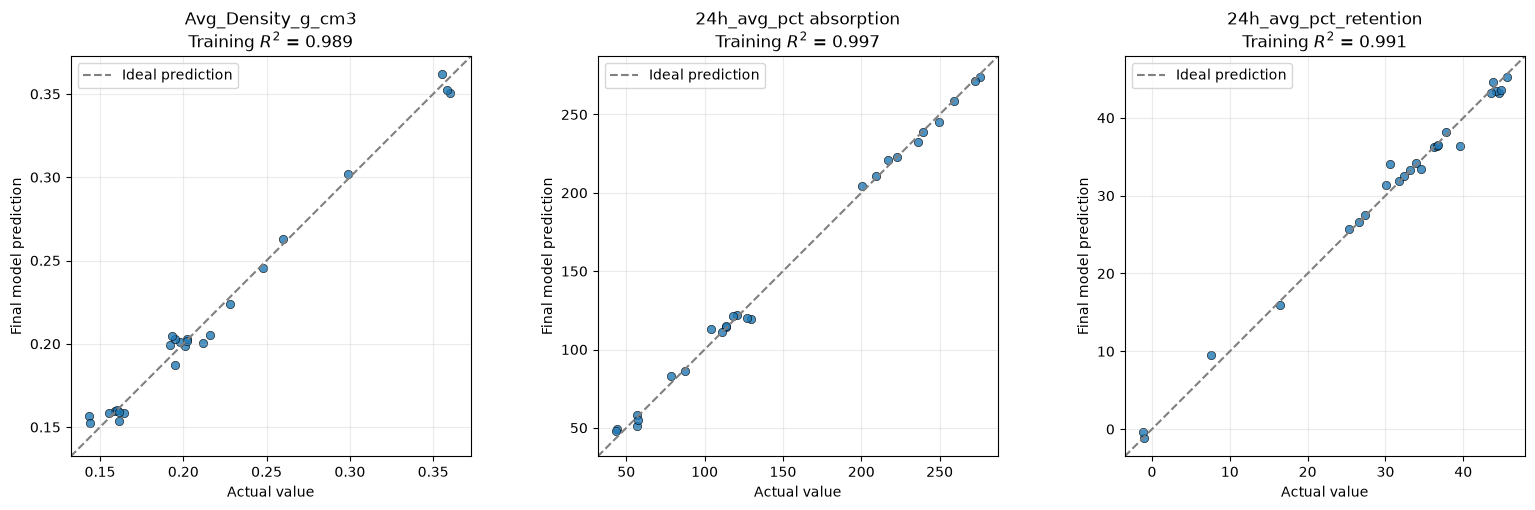

In [ ]:
# Plot predictions from the final GPR estimators fitted on all measured rows per target.
import matplotlib.pyplot as plt

training_predictions = pd.DataFrame(index=model_data.index)
for target in target_cols:
    training_predictions[target] = gpr_models[target].predict(X)

fig, axes = plt.subplots(1, len(target_cols), figsize=(16, 5))

for ax, target in zip(axes, target_cols):
    observed = model_data[target].notna()
    y_true = model_data.loc[observed, target]
    y_pred = training_predictions.loc[observed, target]
    training_r2 = r2_score(y_true, y_pred)
    lower = min(y_true.min(), y_pred.min())
    upper = max(y_true.max(), y_pred.max())
    padding = (upper - lower) * 0.05
    plot_min, plot_max = lower - padding, upper + padding

    ax.scatter(y_true, y_pred, alpha=0.8, edgecolor="black", linewidth=0.5)
    ax.plot(
        [plot_min, plot_max],
        [plot_min, plot_max],
        "--",
        color="gray",
        label="Ideal prediction",
    )
    ax.set_xlim(plot_min, plot_max)
    ax.set_ylim(plot_min, plot_max)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(f"{target}\nTraining $R^2$ = {training_r2:.3f}")
    ax.set_xlabel("Actual value")
    ax.set_ylabel("Final model prediction")
    ax.grid(alpha=0.25)
    ax.legend()

fig.tight_layout()
plt.show()

In [ ]:
# Formula constraints:
# - TEM: 5-8%.
# - Each chain extender (Joncryl, NC513, PEG-DE, NGDE): 0.7-3% when included; 0% when omitted.
# - Combined chain extender amount: no more than 6%.
# - Generate 100,000 valid candidate formulas.
import numpy as np

candidate_count = 100_000
chain_extender_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]
feature_cols = ["TEM", *chain_extender_cols]
rng = np.random.default_rng(42)

candidate_chunks = []
collected = 0
while collected < candidate_count:
    batch_size = max(10_000, 2 * (candidate_count - collected))
    active_counts = rng.integers(1, len(chain_extender_cols) + 1, size=batch_size)
    active_order = rng.random((batch_size, len(chain_extender_cols))).argsort(axis=1)
    active_mask = active_order < active_counts[:, None]
    extender_amounts = rng.uniform(0.7, 3.0, size=(batch_size, len(chain_extender_cols)))
    extender_amounts = np.where(active_mask, extender_amounts, 0.0)

    valid_mask = extender_amounts.sum(axis=1) <= 6.0
    valid_batch = extender_amounts[valid_mask]
    candidate_chunks.append(valid_batch)
    collected += len(valid_batch)

extender_values = np.concatenate(candidate_chunks, axis=0)[:candidate_count]
candidate_set = pd.DataFrame(extender_values, columns=chain_extender_cols)
candidate_set.insert(0, "TEM", rng.uniform(5.0, 8.0, size=candidate_count))
candidate_set = candidate_set[feature_cols]

# Confirm the generated formulas satisfy every requested bound.
assert len(candidate_set) == candidate_count
assert candidate_set["TEM"].between(5.0, 8.0).all()
assert candidate_set[chain_extender_cols].sum(axis=1).le(6.0).all()
for col in chain_extender_cols:
    active = candidate_set[col].ne(0)
    assert candidate_set.loc[active, col].between(0.7, 3.0).all()

print(f"Generated {len(candidate_set):,} valid candidate formulas.")
print(candidate_set.head())
print("Maximum total chain extender:", candidate_set[chain_extender_cols].sum(axis=1).max())

Generated 100,000 valid candidate formulas.
        TEM   Joncryl     NC513    PEG-DE      NGDE
0  7.498286  0.000000  0.000000  2.198651  0.000000
1  6.711942  1.784903  0.787018  1.213481  0.724965
2  5.505915  0.850501  1.969780  2.903304  0.000000
3  5.838431  2.472247  0.000000  1.159775  0.000000
4  5.735430  2.128875  0.000000  0.000000  0.791036
Maximum total chain extender: 5.999979539311976


In [ ]:
# Predict all three properties for every generated candidate formula.
candidate_predictions = candidate_set.copy()

for target in target_cols:
    candidate_predictions[f"predicted_{target}"] = gpr_models[target].predict(
        candidate_set[feature_cols]
    )

assert len(candidate_predictions) == candidate_count
assert all(f"predicted_{target}" in candidate_predictions.columns for target in target_cols)

print(f"Predictions generated for {len(candidate_predictions):,} candidate formulas.")
display(candidate_predictions.head())

Predictions generated for 100,000 candidate formulas.


,TEM,Joncryl,NC513,PEG-DE,NGDE,predicted_Avg_Density_g_cm3,predicted_24h_avg_pct absorption,predicted_24h_avg_pct_retention
0,7.498286,0.000000,0.000000,2.198651,0.000000,0.211892,263.930250,-1.427908
1,6.711942,1.784903,0.787018,1.213481,0.724965,0.214483,164.248133,28.815967
2,5.505915,0.850501,1.969780,2.903304,0.000000,0.232020,199.340182,35.024331
3,5.838431,2.472247,0.000000,1.159775,0.000000,0.215118,138.836635,29.186059
4,5.735430,2.128875,0.000000,0.000000,0.791036,0.215942,103.916927,27.661785


In [ ]:
# Keep candidates that are not dominated on all three predicted properties.
# Objectives: minimize density; maximize 24h absorption and 24h retention.
density_col = "predicted_Avg_Density_g_cm3"
absorption_col = "predicted_24h_avg_pct absorption"
retention_col = "predicted_24h_avg_pct_retention"
objective_cols = [density_col, absorption_col, retention_col]
objective_values = candidate_predictions[objective_cols].to_numpy(dtype=float)
finite_mask = np.isfinite(objective_values).all(axis=1)
finite_indices = np.flatnonzero(finite_mask)
finite_values = objective_values[finite_mask]

# Keep one representative if multiple formulas have identical predicted objectives.
unique_values, first_positions = np.unique(finite_values, axis=0, return_index=True)
original_indices = finite_indices[first_positions]

# Sort by density ascending, then absorption and retention descending.
order = np.lexsort((-unique_values[:, 2], -unique_values[:, 1], unique_values[:, 0]))
sorted_values = unique_values[order]
sorted_indices = original_indices[order]
absorption_levels = np.unique(sorted_values[:, 1])
level_count = len(absorption_levels)
fenwick_max_retention = np.full(level_count + 1, -np.inf)
pareto_indices = []

for row, original_index in zip(sorted_values, sorted_indices):
    density, absorption, retention = row
    absorption_rank = np.searchsorted(absorption_levels, absorption)
    query_index = level_count - absorption_rank

    # Query the best retention among earlier candidates with at least this absorption.
    best_prior_retention = -np.inf
    index = query_index
    while index > 0:
        best_prior_retention = max(best_prior_retention, fenwick_max_retention[index])
        index -= index & -index

    if best_prior_retention < retention:
        pareto_indices.append(original_index)

    # Add this candidate to the prefix-maximum Fenwick tree.
    index = query_index
    while index <= level_count:
        fenwick_max_retention[index] = max(fenwick_max_retention[index], retention)
        index += index & -index

pareto_candidates = candidate_predictions.iloc[pareto_indices].copy()
assert len(pareto_candidates) > 0
assert pareto_candidates["TEM"].between(5.0, 8.0).all()
assert pareto_candidates[chain_extender_cols].sum(axis=1).le(6.0).all()

# These three frontier members show the single-objective extremes and trade-offs.
pareto_extremes = pd.concat(
    [
        pareto_candidates.loc[[pareto_candidates[density_col].idxmin()]],
        pareto_candidates.loc[[pareto_candidates[absorption_col].idxmax()]],
        pareto_candidates.loc[[pareto_candidates[retention_col].idxmax()]],
    ]
).drop_duplicates()

print(f"Found {len(pareto_candidates):,} Pareto-optimal formulas out of {len(candidate_predictions):,} candidates.")
print("Pareto-front extremes (lowest density, highest absorption, highest retention):")
display(pareto_extremes[feature_cols + objective_cols])
print("\nFirst 20 Pareto candidates, ordered by predicted density:")
display(
    pareto_candidates.sort_values(density_col)[feature_cols + objective_cols].head(20)
)

Found 114 Pareto-optimal formulas out of 100,000 candidates.
Pareto-front extremes (lowest density, highest absorption, highest retention):


,TEM,Joncryl,NC513,PEG-DE,NGDE,predicted_Avg_Density_g_cm3,predicted_24h_avg_pct absorption,predicted_24h_avg_pct_retention
33602,7.967423,1.195205,0.000000,2.828116,0.000000,0.148309,197.872791,41.030411
65322,7.990858,0.000000,0.000000,1.363412,0.000000,0.201917,281.044991,3.707913
82564,5.004008,0.000000,1.190539,0.000000,2.434799,0.328465,82.400401,46.458564



First 20 Pareto candidates, ordered by predicted density:


,TEM,Joncryl,NC513,PEG-DE,NGDE,predicted_Avg_Density_g_cm3,predicted_24h_avg_pct absorption,predicted_24h_avg_pct_retention
33602,7.967423,1.195205,0.000000,2.828116,0.0,0.148309,197.872791,41.030411
3475,7.982344,1.214672,0.000000,1.908033,0.0,0.148338,196.925830,42.546386
9421,7.994052,1.104685,0.000000,2.552930,0.0,0.149978,203.040008,43.258743
48689,7.984946,0.851359,2.738995,1.830220,0.0,0.151660,233.675577,35.426820
26191,7.994754,1.102542,0.000000,1.236263,0.0,0.151703,202.877462,43.584089
98210,7.953490,0.841701,2.964560,1.658972,0.0,0.152479,237.332799,35.416135
1955,7.987890,1.018809,2.570147,1.140126,0.0,0.153319,234.298487,36.808494
22309,7.925018,0.722941,2.788564,1.143174,0.0,0.153422,239.282245,36.135939
55700,7.979391,1.029388,0.000000,2.763521,0.0,0.154298,206.031525,42.396420
21398,7.922092,0.940514,2.600155,0.890985,0.0,0.155120,224.773359,37.125613
